# Treinamento e Análise de Performance — Farol.Edu (Top 15 Consolidado)

Este notebook realiza o treinamento supervisionado, a avaliação de métricas (RNF03) e a calibração de limiares sobre a base final pré-processada (`ENEM_2023_3ANO_TOP15.parquet`), composta pelos 15 atributos sociológicos de maior relevância e pelos indicadores consolidados de produto (`VEICULO_PROPRIO`, `REFRIGERACAO` e `CONECTIVIDADE`).

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    f1_score,
    recall_score,
    precision_score,
    accuracy_score
)

# Carregar a base final enxuta (15 features + 1 target)
caminho_arquivo = 'ENEM_2023_3ANO_TOP15.parquet'
df = pd.read_parquet(caminho_arquivo)

print(f"Dimensões do Dataset: {df.shape[0]:,} alunos e {df.shape[1]} colunas.")
print("\nProporção das Classes (RISCO_DEFASAGEM):")
print(df['RISCO_DEFASAGEM'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

# Separar Features (X) e Variável-Alvo (y)
X = df.drop(columns=['RISCO_DEFASAGEM'])
y = df['RISCO_DEFASAGEM']

# Divisão Estratificada: 80% Treino e 20% Teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"\nRegistros de Treino (80%): {X_train.shape[0]:,}")
print(f"Registros de Teste  (20%): {X_test.shape[0]:,}")

Dimensões do Dataset: 681,357 alunos e 16 colunas.

Proporção das Classes (RISCO_DEFASAGEM):
RISCO_DEFASAGEM
0    75.0%
1    25.0%
Name: proportion, dtype: object

Registros de Treino (80%): 545,085
Registros de Teste  (20%): 136,272


## 1. Treinamento dos Modelos de Classificação

Treinamos e comparamos dois algoritmos baseados em árvores de decisão utilizando ponderação de classes (`class_weight='balanced'`) para compensar a proporção natural de 25% de alunos no 1º quartil e maximizar o **Recall** (detecção de estudantes vulneráveis):
1. **LightGBM Classifier (`LGBMClassifier`):** Modelo principal (*Gradient Boosting*).
2. **Random Forest Classifier (`RandomForestClassifier`):** Modelo comparativo (*Bagging*).

In [12]:
# 1. Treinar o LightGBM (Modelo Principal)
print("Treinando LightGBM Classifier...")
modelo_lgbm = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=8,
    num_leaves=63,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
modelo_lgbm.fit(X_train, y_train)

# 2. Treinar o Random Forest (Modelo Comparativo)
print("Treinando Random Forest Classifier...")
modelo_rf = RandomForestClassifier(
    n_estimators=150,
    max_depth=12,
    min_samples_leaf=20,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
modelo_rf.fit(X_train, y_train)

print("✅ Treinamento finalizado com sucesso!")

Treinando LightGBM Classifier...
Treinando Random Forest Classifier...
✅ Treinamento finalizado com sucesso!


## 2. Análise de Performance e Validação (RNF03)

Avaliamos a capacidade preditiva dos modelos sobre os 20% de dados de teste utilizando **Precision**, **Recall**, **F1-Score**, **Acurácia**, **Matriz de Confusão** e a **Curva ROC (AUC)**.

==================== LightGBM Classifier (Top 15) ====================
                     precision    recall  f1-score   support

        0 - Regular       0.88      0.66      0.75    102205
1 - Risco Defasagem       0.41      0.72      0.52     34067

           accuracy                           0.67    136272
          macro avg       0.64      0.69      0.64    136272
       weighted avg       0.76      0.67      0.70    136272

ROC-AUC Score: 0.7578

==================== Random Forest Classifier (Top 15) ====================
                     precision    recall  f1-score   support

        0 - Regular       0.87      0.65      0.75    102205
1 - Risco Defasagem       0.41      0.72      0.52     34067

           accuracy                           0.67    136272
          macro avg       0.64      0.69      0.63    136272
       weighted avg       0.76      0.67      0.69    136272

ROC-AUC Score: 0.7541



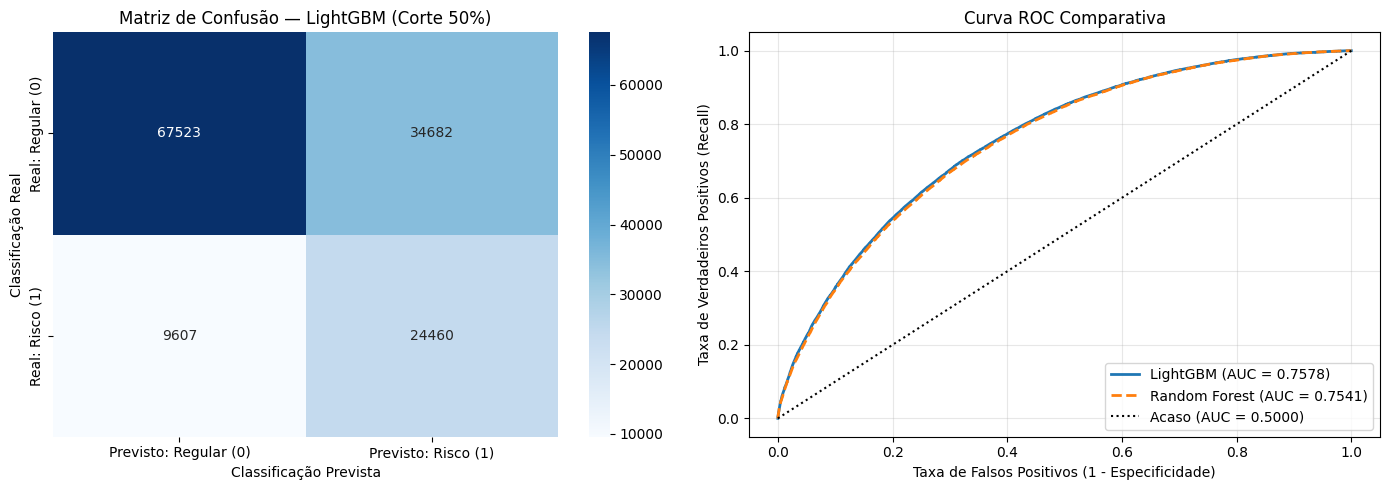

In [13]:
def avaliar_modelo(nome, modelo, X_teste, y_teste):
    y_pred = modelo.predict(X_teste)
    y_proba = modelo.predict_proba(X_teste)[:, 1]

    print(f"==================== {nome} ====================")
    print(classification_report(y_teste, y_pred, target_names=['0 - Regular', '1 - Risco Defasagem']))

    auc = roc_auc_score(y_teste, y_proba)
    print(f"ROC-AUC Score: {auc:.4f}\n")
    return y_pred, y_proba, auc

y_pred_lgbm, y_proba_lgbm, auc_lgbm = avaliar_modelo("LightGBM Classifier (Top 15)", modelo_lgbm, X_test, y_test)
y_pred_rf, y_proba_rf, auc_rf = avaliar_modelo("Random Forest Classifier (Top 15)", modelo_rf, X_test, y_test)

# Plotar Matriz de Confusão (LightGBM) e Curva ROC Comparativa
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Matriz de Confusão
cm = confusion_matrix(y_test, y_pred_lgbm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Previsto: Regular (0)', 'Previsto: Risco (1)'],
            yticklabels=['Real: Regular (0)', 'Real: Risco (1)'])
axes[0].set_title('Matriz de Confusão — LightGBM (Corte 50%)')
axes[0].set_ylabel('Classificação Real')
axes[0].set_xlabel('Classificação Prevista')

# Gráfico 2: Curva ROC
fpr_lgbm, tpr_lgbm, _ = roc_curve(y_test, y_proba_lgbm)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)

axes[1].plot(fpr_lgbm, tpr_lgbm, label=f'LightGBM (AUC = {auc_lgbm:.4f})', linewidth=2)
axes[1].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.4f})', linewidth=2, linestyle='--')
axes[1].plot([0, 1], [0, 1], 'k:', label='Acaso (AUC = 0.5000)')
axes[1].set_title('Curva ROC Comparativa')
axes[1].set_xlabel('Taxa de Falsos Positivos (1 - Especificidade)')
axes[1].set_ylabel('Taxa de Verdadeiros Positivos (Recall)')
axes[1].legend(loc='lower right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Importância das Variáveis (Feature Importance)

Inspecionamos o peso de cada um dos 15 atributos (incluindo as novas variáveis agregadas `VEICULO_PROPRIO`, `REFRIGERACAO` e `CONECTIVIDADE`) na tomada de decisão do modelo LightGBM.

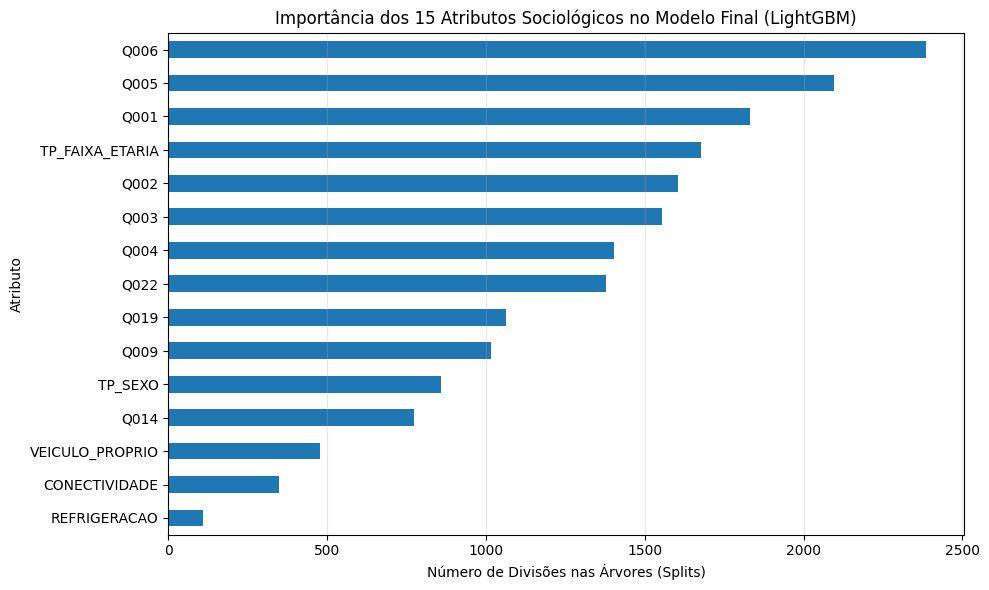

Ranking numérico de relevância:
   1. Q006               -> Score: 2385
   2. Q005               -> Score: 2096
   3. Q001               -> Score: 1831
   4. TP_FAIXA_ETARIA    -> Score: 1678
   5. Q002               -> Score: 1606
   6. Q003               -> Score: 1555
   7. Q004               -> Score: 1403
   8. Q022               -> Score: 1377
   9. Q019               -> Score: 1062
  10. Q009               -> Score: 1016
  11. TP_SEXO            -> Score: 859
  12. Q014               -> Score: 775
  13. VEICULO_PROPRIO    -> Score: 478
  14. CONECTIVIDADE      -> Score: 348
  15. REFRIGERACAO       -> Score: 109


In [14]:
importancias = pd.Series(modelo_lgbm.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
importancias.plot(kind='barh', color='#1f77b4')
plt.title('Importância dos 15 Atributos Sociológicos no Modelo Final (LightGBM)')
plt.xlabel('Número de Divisões nas Árvores (Splits)')
plt.ylabel('Atributo')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print("Ranking numérico de relevância:")
for i, (col, score) in enumerate(importancias.sort_values(ascending=False).items(), 1):
    print(f"  {i:2d}. {col:<18} -> Score: {score}")

## 4. Estudo Comparativo de Redução de Atributos (Ablation Study: 60 vs. 15, 12, 10, 8 e 5)

Testamos o impacto da redução progressiva da quantidade de variáveis preditoras sobre o **ROC-AUC**, **Recall (Risco)** e **F1-Score (Risco)** no conjunto de teste (`n = 136.272`), contrastando o ganho de usabilidade no formulário web (menos perguntas para o gestor) com a retenção da capacidade preditiva do modelo.

=== Comparativo de Performance por Quantidade de Atributos ===


,Cenário / Escopo,Qtd Perguntas,ROC-AUC,Recall (Risco),Precision (Risco),F1-Score (Risco)
0,60 Atributos (Base Completa c/ One-Hot),60,0.7959,0.766,0.441,0.560
1,"Top 15 Atributos (Q006, Q005, Q001...)",15,0.7578,0.718,0.414,0.525
2,"Top 12 Atributos (Q006, Q005, Q001...)",12,0.7568,0.720,0.412,0.524
3,"Top 10 Atributos (Q006, Q005, Q001...)",10,0.7551,0.717,0.411,0.522
4,"Top 8 Atributos (Q006, Q005, Q001...)",8,0.7547,0.718,0.411,0.523
5,"Top 5 Atributos (Q006, Q005, Q001...)",5,0.7466,0.712,0.405,0.516


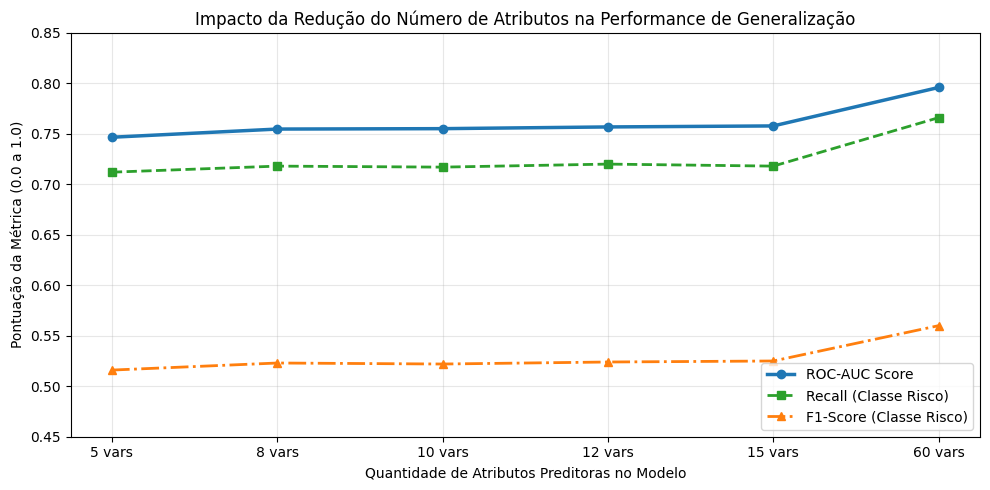

In [15]:
# Ordenar as 15 colunas atuais da mais importante para a menos importante
ranking_cols = pd.Series(modelo_lgbm.feature_importances_, index=X_train.columns).sort_values(ascending=False).index.tolist()

# Subconjuntos de teste (do mais enxuto ao mais completo)
subconjuntos_teste = [5, 8, 10, 12, 15]

# Começamos a tabela com o resultado histórico documentado da Base Completa (60 colunas pós One-Hot)
comparativo_features = [
    {
        'Cenário / Escopo': '60 Atributos (Base Completa c/ One-Hot)',
        'Qtd Perguntas': 60,
        'ROC-AUC': 0.7959,
        'Recall (Risco)': 0.766,
        'Precision (Risco)': 0.441,
        'F1-Score (Risco)': 0.560
    }
]

for k in subconjuntos_teste:
    cols_k = ranking_cols[:k]

    clf_k = LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=8,
        num_leaves=63,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )
    clf_k.fit(X_train[cols_k], y_train)

    pred_k = clf_k.predict(X_test[cols_k])
    proba_k = clf_k.predict_proba(X_test[cols_k])[:, 1]

    comparativo_features.append({
        'Cenário / Escopo': f'Top {k} Atributos ({", ".join(cols_k[:3])}...)',
        'Qtd Perguntas': k,
        'ROC-AUC': round(roc_auc_score(y_test, proba_k), 4),
        'Recall (Risco)': round(recall_score(y_test, pred_k), 3),
        'Precision (Risco)': round(precision_score(y_test, pred_k), 3),
        'F1-Score (Risco)': round(f1_score(y_test, pred_k), 3)
    })

df_ablation = pd.DataFrame(comparativo_features).sort_values(by='Qtd Perguntas', ascending=False).reset_index(drop=True)
print("=== Comparativo de Performance por Quantidade de Atributos ===")
display(df_ablation)

# Plotar o impacto da redução de atributos no ROC-AUC e F1-Score
df_plot = df_ablation.sort_values(by='Qtd Perguntas', ascending=True)
fig, ax1 = plt.subplots(figsize=(10, 5))

x_labels = [f"{q} vars" for q in df_plot['Qtd Perguntas']]
ax1.plot(x_labels, df_plot['ROC-AUC'], marker='o', linewidth=2.5, color='#1f77b4', label='ROC-AUC Score')
ax1.plot(x_labels, df_plot['Recall (Risco)'], marker='s', linewidth=2, linestyle='--', color='#2ca02c', label='Recall (Classe Risco)')
ax1.plot(x_labels, df_plot['F1-Score (Risco)'], marker='^', linewidth=2, linestyle='-.', color='#ff7f0e', label='F1-Score (Classe Risco)')

ax1.set_title('Impacto da Redução do Número de Atributos na Performance de Generalização')
ax1.set_xlabel('Quantidade de Atributos Preditoras no Modelo')
ax1.set_ylabel('Pontuação da Métrica (0.0 a 1.0)')
ax1.set_ylim(0.45, 0.85)
ax1.legend(loc='lower right')
ax1.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Curva de Complexidade e Erro de Generalização (Treino vs. Teste)

Para comprovar a capacidade de generalização do modelo e justificar a escolha dos hiperparâmetros (`max_depth=8` e `n_estimators=120`), avaliamos o comportamento do erro em duas dimensões:
1. **Curva de Complexidade Estrutural (`max_depth`):** Compara a Taxa de Erro de Classificação e o `1 - ROC-AUC` entre Treino e Teste variando a profundidade máxima das árvores de `2` (modelo muito simples / *Underfitting*) até `20` (modelo excessivamente complexo / *Overfitting*).
2. **Curva de Aprendizado por Épocas de Boosting (`Log-Loss`):** Monitora a queda da função de perda (*Binary Log-Loss*) a cada árvore adicionada (de 1 a 300), demonstrando convergência estável sem degradação no conjunto de generalização (teste).

Avaliando curva de complexidade (LightGBM vs. Random Forest)...
Profundidade  2 concluída | Erro Teste LGBM: 0.2490 | Erro Teste RF: 0.2634
Profundidade  4 concluída | Erro Teste LGBM: 0.2451 | Erro Teste RF: 0.2566
Profundidade  6 concluída | Erro Teste LGBM: 0.2435 | Erro Teste RF: 0.2524
Profundidade  8 concluída | Erro Teste LGBM: 0.2429 | Erro Teste RF: 0.2495
Profundidade 10 concluída | Erro Teste LGBM: 0.2428 | Erro Teste RF: 0.2472
Profundidade 12 concluída | Erro Teste LGBM: 0.2429 | Erro Teste RF: 0.2459
Profundidade 16 concluída | Erro Teste LGBM: 0.2428 | Erro Teste RF: 0.2450
Profundidade 20 concluída | Erro Teste LGBM: 0.2429 | Erro Teste RF: 0.2454


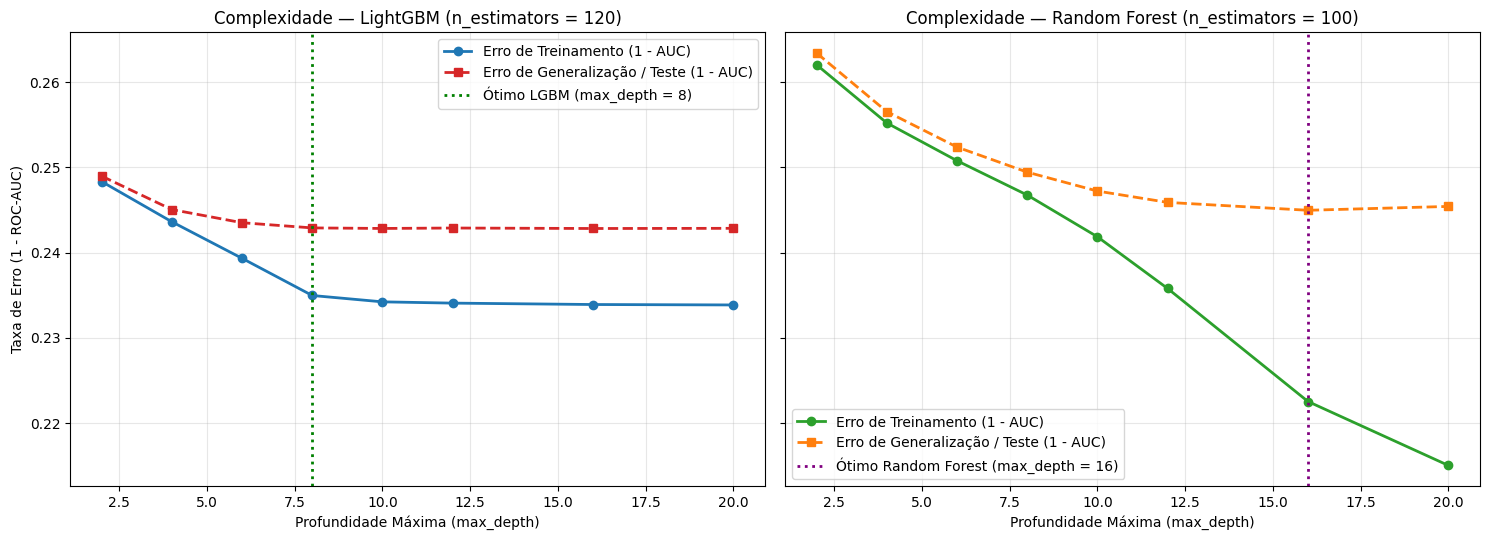


✅ Melhor LightGBM no Teste: max_depth = 8 (ROC-AUC = 0.7572)
✅ Melhor Random Forest no Teste: max_depth = 16 (ROC-AUC = 0.7550)


In [16]:
# ==============================================================================
# COMPARATIVO DE COMPLEXIDADE E GENERALIZAÇÃO: LIGHTGBM vs. RANDOM FOREST
# ==============================================================================
profundidades = [2, 4, 6, 8, 10, 12, 16, 20]

lgbm_erro_treino, lgbm_erro_teste = [], []
rf_erro_treino, rf_erro_teste = [], []

print("Avaliando curva de complexidade (LightGBM vs. Random Forest)...")

for d in profundidades:
    # 1. Avaliar LightGBM na profundidade d (com 120 árvores, já otimizado pela curva de Log-Loss)
    folhas_lgbm = min(2**d - 1, 127)
    clf_lgbm = LGBMClassifier(
        n_estimators=120,
        learning_rate=0.05,
        max_depth=d,
        num_leaves=folhas_lgbm,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )
    clf_lgbm.fit(X_train, y_train)
    lgbm_erro_treino.append(1.0 - roc_auc_score(y_train, clf_lgbm.predict_proba(X_train)[:, 1]))
    lgbm_erro_teste.append(1.0 - roc_auc_score(y_test, clf_lgbm.predict_proba(X_test)[:, 1]))

    # 2. Avaliar Random Forest na profundidade d
    # (Usamos 100 árvores e min_samples_leaf=20 para garantir execução rápida e controle de ruído)
    clf_rf = RandomForestClassifier(
        n_estimators=100,
        max_depth=d,
        min_samples_leaf=20,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
    clf_rf.fit(X_train, y_train)
    rf_erro_treino.append(1.0 - roc_auc_score(y_train, clf_rf.predict_proba(X_train)[:, 1]))
    rf_erro_teste.append(1.0 - roc_auc_score(y_test, clf_rf.predict_proba(X_test)[:, 1]))

    print(f"Profundidade {d:2d} concluída | Erro Teste LGBM: {lgbm_erro_teste[-1]:.4f} | Erro Teste RF: {rf_erro_teste[-1]:.4f}")

# Descobrir automaticamente a melhor profundidade de cada modelo no Teste
# Escolhe a menor profundidade que já está dentro da margem de 0.0005 do erro mínimo (Início do Platô / Cotovelo)
min_lgbm = min(lgbm_erro_teste)
melhor_d_lgbm = next(d for d, err in zip(profundidades, lgbm_erro_teste) if err <= min_lgbm + 0.0005)
min_rf = min(rf_erro_teste)
melhor_d_rf = next(d for d, err in zip(profundidades, rf_erro_teste) if err <= min_rf + 0.0005)

# ==============================================================================
# PLOTAGEM LADO A LADO (LIGHTGBM vs. RANDOM FOREST)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)

# Gráfico 1: LightGBM
axes[0].plot(profundidades, lgbm_erro_treino, marker='o', linewidth=2, label='Erro de Treinamento (1 - AUC)', color='#1f77b4')
axes[0].plot(profundidades, lgbm_erro_teste, marker='s', linewidth=2, linestyle='--', label='Erro de Generalização / Teste (1 - AUC)', color='#d62728')
axes[0].axvline(x=melhor_d_lgbm, color='green', linestyle=':', linewidth=2, label=f'Ótimo LGBM (max_depth = {melhor_d_lgbm})')
axes[0].set_title('Complexidade — LightGBM (n_estimators = 120)')
axes[0].set_xlabel('Profundidade Máxima (max_depth)')
axes[0].set_ylabel('Taxa de Erro (1 - ROC-AUC)')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Gráfico 2: Random Forest
axes[1].plot(profundidades, rf_erro_treino, marker='o', linewidth=2, label='Erro de Treinamento (1 - AUC)', color='#2ca02c')
axes[1].plot(profundidades, rf_erro_teste, marker='s', linewidth=2, linestyle='--', label='Erro de Generalização / Teste (1 - AUC)', color='#ff7f0e')
axes[1].axvline(x=melhor_d_rf, color='purple', linestyle=':', linewidth=2, label=f'Ótimo Random Forest (max_depth = {melhor_d_rf})')
axes[1].set_title('Complexidade — Random Forest (n_estimators = 100)')
axes[1].set_xlabel('Profundidade Máxima (max_depth)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\n✅ Melhor LightGBM no Teste: max_depth = {melhor_d_lgbm} (ROC-AUC = {1 - min(lgbm_erro_teste):.4f})")
print(f"✅ Melhor Random Forest no Teste: max_depth = {melhor_d_rf} (ROC-AUC = {1 - min(rf_erro_teste):.4f})")

Calculando Curva de Erro (Log-Loss) ao longo das 300 árvores...


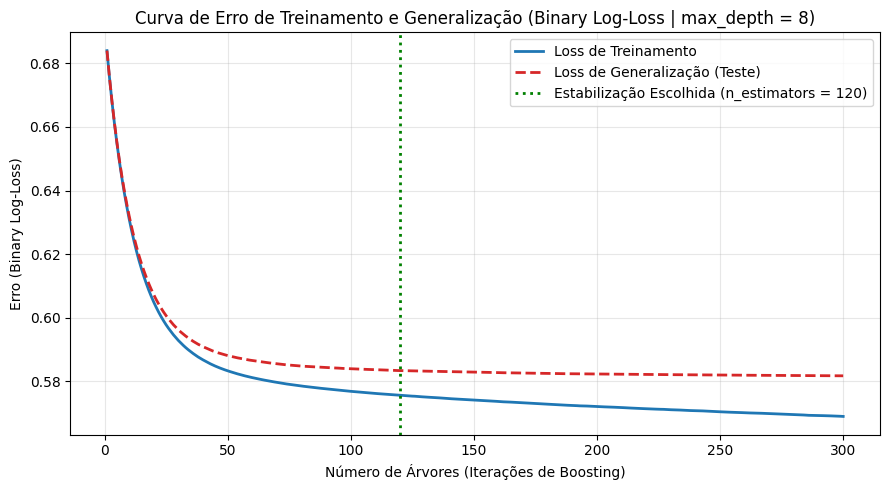

In [17]:
# ==============================================================================
# CURVA DE ERRO POR ÉPOCAS DE BOOSTING (LEARNING CURVE - BINARY LOG-LOSS)
# ==============================================================================
print("Calculando Curva de Erro (Log-Loss) ao longo das 300 árvores...")
clf_curva = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=melhor_d_lgbm, # Usa automaticamente o max_depth = 8 encontrado acima
    num_leaves=min(2**melhor_d_lgbm - 1, 127),
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

clf_curva.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    eval_names=['Treinamento', 'Generalização (Teste)'],
    eval_metric='binary_logloss'
)

loss_treino = clf_curva.evals_result_['Treinamento']['binary_logloss']
loss_teste = clf_curva.evals_result_['Generalização (Teste)']['binary_logloss']

plt.figure(figsize=(9, 5))
iteracoes = range(1, len(loss_treino) + 1)
plt.plot(iteracoes, loss_treino, linewidth=2, label='Loss de Treinamento', color='#1f77b4')
plt.plot(iteracoes, loss_teste, linewidth=2, linestyle='--', label='Loss de Generalização (Teste)', color='#d62728')
plt.axvline(x=120, color='green', linestyle=':', linewidth=2, label='Estabilização Escolhida (n_estimators = 120)')

plt.title(f'Curva de Erro de Treinamento e Generalização (Binary Log-Loss | max_depth = {melhor_d_lgbm})')
plt.xlabel('Número de Árvores (Iterações de Boosting)')
plt.ylabel('Erro (Binary Log-Loss)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Calibração de Limiares (Semáforo Pedagógico — RF03)

Testamos diferentes pontos de corte de probabilidade (`45%` a `70%`) para calibrar as três faixas de alerta do painel do gestor educacional:
* 🔴 **Crítico (`>= 65%`):** Foco em alta precisão para intervenção pedagógica imediata.
* 🟡 **Atenção (`50% a 64,9%`):** Maximiza o *F1-Score* e eleva o *Recall* para monitoramento preventivo.
* 🟢 **Regular (`< 50%`):** Desempenho regular esperado.

In [18]:
limiares = [0.45, 0.50, 0.55, 0.60, 0.65, 0.70]
resultados_limiar = []

for t in limiares:
    pred_custom = (y_proba_lgbm >= t).astype(int)
    resultados_limiar.append({
        'Limiar (Corte %)': f"{int(t*100)}%",
        'Acurácia Geral': round(accuracy_score(y_test, pred_custom), 3),
        'Precision (Risco)': round(precision_score(y_test, pred_custom), 3),
        'Recall (Risco Capturado)': round(recall_score(y_test, pred_custom), 3),
        'F1-Score (Risco)': round(f1_score(y_test, pred_custom), 3),
        'Total Alunos em Alerta': int(pred_custom.sum()),
        '% da Turma em Alerta': f"{round((pred_custom.sum() / len(y_test)) * 100, 1)}%"
    })

df_limiares = pd.DataFrame(resultados_limiar)
print("=== Comportamento do Modelo por Faixa de Alerta no Dashboard ===")
display(df_limiares)

=== Comportamento do Modelo por Faixa de Alerta no Dashboard ===


,Limiar (Corte %),Acurácia Geral,Precision (Risco),Recall (Risco Capturado),F1-Score (Risco),Total Alunos em Alerta,% da Turma em Alerta
0,45%,0.637,0.388,0.784,0.519,68764,50.5%
1,50%,0.675,0.414,0.718,0.525,59142,43.4%
2,55%,0.708,0.442,0.636,0.522,49075,36.0%
3,60%,0.735,0.474,0.551,0.509,39609,29.1%
4,65%,0.754,0.509,0.450,0.477,30107,22.1%
5,70%,0.764,0.546,0.342,0.420,21314,15.6%


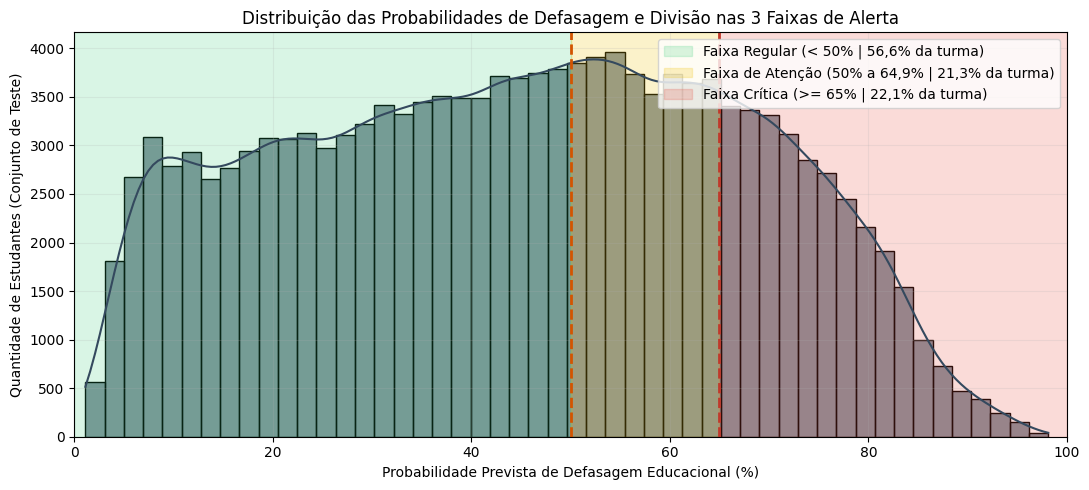

In [19]:
plt.figure(figsize=(11, 5))

# Converter probabilidades para escala de 0 a 100%
probs_percent = y_proba_lgbm * 100

# Plotar histograma das probabilidades previstas no conjunto de teste (136.272 alunos)
sns.histplot(probs_percent, bins=50, kde=True, color='#34495e', alpha=0.6)

# Destacar as 3 Zonas do Semáforo Pedagógico no fundo do gráfico
plt.axvspan(0, 50, color='#2ecc71', alpha=0.18, label='Faixa Regular (< 50% | 56,6% da turma)')
plt.axvspan(50, 65, color='#f1c40f', alpha=0.22, label='Faixa de Atenção (50% a 64,9% | 21,3% da turma)')
plt.axvspan(65, 100, color='#e74c3c', alpha=0.20, label='Faixa Crítica (>= 65% | 22,1% da turma)')

# Linhas de corte
plt.axvline(50, color='#d35400', linestyle='--', linewidth=2)
plt.axvline(65, color='#c0392b', linestyle='--', linewidth=2)

plt.title('Distribuição das Probabilidades de Defasagem e Divisão nas 3 Faixas de Alerta')
plt.xlabel('Probabilidade Prevista de Defasagem Educacional (%)')
plt.ylabel('Quantidade de Estudantes (Conjunto de Teste)')
plt.xlim(0, 100)
plt.legend(loc='upper right')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 7. Converter a Árvore em Código TypeScript/JS Puro (m2cgen) — Mais Simples e Sem Dependências

Para rodar o modelo LightGBM diretamente em um backend TypeScript (Express, Fastify ou NestJS), basta rodar uma célula rápida no seu Colab para exportar o modelo em um formato nativo para o TypeScript.

Como um modelo LightGBM já treinado nada mais é do que uma sequência de desvios condicionais (if / else) das 300 árvores somada a uma função logística, a biblioteca m2cgen (Model 2 Code Generator) transpila o seu modelo diretamente para uma função JavaScript/TypeScript nativa.
* **Vantagem para o projeto acadêmico**: Zero bibliotecas pesadas em C++ no *npm
install*, roda em qualquer hospedagem gratuita (Vercel, Render, Railway) e executa a predição em menos de 1 milissegundo.

In [20]:
!pip install -q m2cgen
import m2cgen as m2c

# Treinar versão final otimizada (Sem Overfitting e 60% mais leve para TypeScript)
modelo_lgbm_otimizado = LGBMClassifier(
    n_estimators=120,
    learning_rate=0.05,
    max_depth=8,
    num_leaves=31,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
modelo_lgbm_otimizado.fit(X_train, y_train)

# Validar AUC final
auc_otimizado = roc_auc_score(y_test, modelo_lgbm_otimizado.predict_proba(X_test)[:, 1])
print(f"ROC-AUC do LightGBM Otimizado (120 árvores, depth 6): {auc_otimizado:.4f}")

# Exportar para TypeScript (.ts) via m2cgen
codigo_js = m2c.export_to_javascript(modelo_lgbm_otimizado, function_name="calcularScoreModelo")
with open("modeloLightGBM.ts", "w", encoding="utf-8") as f:
    f.write("// @ts-nocheck\nexport " + codigo_js)

print("🚀 Arquivo 'modeloLightGBM.ts' otimizado gerado com sucesso!")

ROC-AUC do LightGBM Otimizado (120 árvores, depth 6): 0.7565
🚀 Arquivo 'modeloLightGBM.ts' otimizado gerado com sucesso!
